In [2]:
import pandas as pd

df = pd.read_excel("milk yield and composition.xlsx")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 750
Number of columns: 13


In [2]:
print(df.dtypes)

Animal ID                   int64
Genetic Group              object
THI Range                  object
Replication No              int64
DMI (kg)                  float64
Milk Yield (L/day/cow)    float64
SCC cells per mL            int64
Fat%                      float64
SNF%                      float64
Protein %                 float64
Salt%                     float64
Lactose%                  float64
pH                        float64
dtype: object


In [3]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

if df.isnull().sum().sum() == 0:
    print("The dataset is complete. There are no missing values.")
else:
    print("The dataset is not complete. It contains missing values.")

Missing values in each column:
Animal ID                 0
Genetic Group             0
THI Range                 0
Replication No            0
DMI (kg)                  0
Milk Yield (L/day/cow)    0
SCC cells per mL          0
Fat%                      0
SNF%                      0
Protein %                 0
Salt%                     0
Lactose%                  0
pH                        0
dtype: int64

Total missing values: 0
The dataset is complete. There are no missing values.


In [4]:
first_15 = df.head(15)
last_20 = df.tail(20)

df_sample = pd.concat([first_15, last_20])

print(df_sample)

     Animal ID Genetic Group THI Range  Replication No  DMI (kg)  \
0          102         Local        T0               1      6.91   
1          102         Local        T0               2      6.61   
2          102         Local        T0               3      7.31   
3          102         Local        T0               4      6.75   
4          102         Local        T0               5      6.42   
5          102         Local        T1               1      6.46   
6          102         Local        T1               2      5.76   
7          102         Local        T1               3      6.93   
8          102         Local        T1               4      6.10   
9          102         Local        T1               5      6.70   
10         102         Local        T2               1      6.12   
11         102         Local        T2               2      6.30   
12         102         Local        T2               3      6.44   
13         102         Local        T2          

In [3]:
# Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

# Display summary statistics
display(df.describe())

# Check the unique categories in the dataset
print("Genetic Groups:", df["Genetic Group"].unique())
print("THI Ranges:", df["THI Range"].unique())

Number of duplicate rows: 0


,Animal ID,Replication No,DMI (kg),Milk Yield (L/day/cow),SCC cells per mL,Fat%,SNF%,Protein %,Salt%,Lactose%,pH
count,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000
mean,306.500000,3.000000,10.049600,5.529413,218884.000000,3.564587,8.445160,3.096093,0.688929,4.641533,6.909853
std,141.544916,1.415157,2.462994,2.572433,48790.783947,0.281956,0.686292,0.210662,0.043749,0.310787,0.096147
min,102.000000,1.000000,4.480000,0.300000,97000.000000,2.870000,6.330000,2.460000,0.589000,3.700000,6.670000
25%,204.000000,2.000000,8.800000,4.455000,185000.000000,3.362500,7.960000,2.960000,0.656250,4.420000,6.850000
50%,306.500000,3.000000,10.150000,5.805000,217500.000000,3.560000,8.420000,3.090000,0.687000,4.620000,6.900000
75%,409.000000,4.000000,11.885000,7.175000,253000.000000,3.780000,8.887500,3.230000,0.717000,4.860000,6.980000
max,511.000000,5.000000,14.820000,10.470000,364000.000000,4.310000,10.380000,3.600000,0.820000,5.500000,7.160000


Genetic Groups: ['Local' 'HF50' 'HF62.5' 'HF75' 'HF87.5']
THI Ranges: ['T0' 'T1' 'T2']


In [5]:
print(df.columns.tolist())

['Animal ID', 'Genetic Group', 'THI Range', 'Replication No', 'DMI (kg)', 'Milk Yield (L/day/cow)', 'SCC cells per mL', 'Fat%', 'SNF%', 'Protein %', 'Salt%', 'Lactose%', 'pH']


In [6]:
print("Unique animals:", df["Animal ID"].nunique())

print("\nRecords per replication:")
print(df["Replication No"].value_counts().sort_index())

print("\nRecords per animal:")
print(df["Animal ID"].value_counts().value_counts().sort_index())

Unique animals: 50

Records per replication:
Replication No
1    150
2    150
3    150
4    150
5    150
Name: count, dtype: int64

Records per animal:
count
15    50
Name: count, dtype: int64


In [7]:
print("Unique DMI values:", df["DMI (kg)"].nunique())
print("Unique THI ranges:", df["THI Range"].unique())
print("Unique genetic groups:", df["Genetic Group"].unique())

print("\nGenetic groups per animal:")
print(df.groupby("Animal ID")["Genetic Group"].nunique().value_counts())

print("\nTHI ranges per animal:")
print(df.groupby("Animal ID")["THI Range"].nunique().value_counts())

Unique DMI values: 513
Unique THI ranges: ['T0' 'T1' 'T2']
Unique genetic groups: ['Local' 'HF50' 'HF62.5' 'HF75' 'HF87.5']

Genetic groups per animal:
Genetic Group
1    50
Name: count, dtype: int64

THI ranges per animal:
THI Range
3    50
Name: count, dtype: int64


In [8]:
print("Average milk yield by THI range:")
display(
    df.groupby("THI Range")["Milk Yield (L/day/cow)"]
    .agg(["count", "mean", "std"])
    .round(2)
)

print("\nAverage milk yield by genetic group:")
display(
    df.groupby("Genetic Group")["Milk Yield (L/day/cow)"]
    .agg(["count", "mean", "std"])
    .round(2)
)

Average milk yield by THI range:


,count,mean,std
THI Range,,,
T0,250,5.99,2.54
T1,250,5.57,2.55
T2,250,5.03,2.54



Average milk yield by genetic group:


,count,mean,std
Genetic Group,,,
HF50,150,5.09,0.70
HF62.5,150,5.59,0.73
HF75,150,6.61,0.76
HF87.5,150,8.98,0.67
Local,150,1.37,0.64


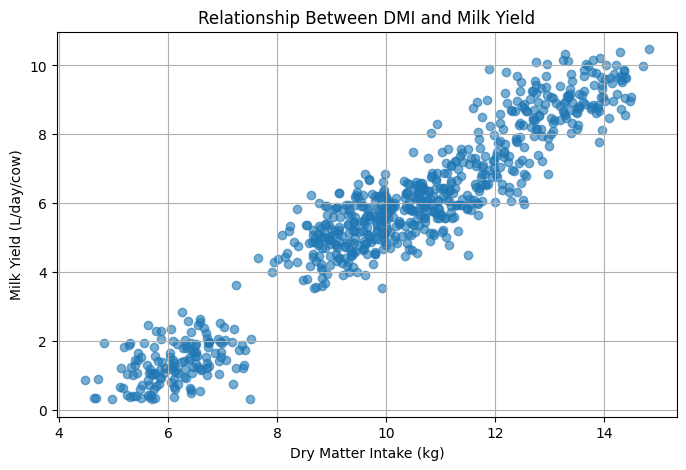

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["DMI (kg)"],
    df["Milk Yield (L/day/cow)"],
    alpha=0.6
)

plt.xlabel("Dry Matter Intake (kg)")
plt.ylabel("Milk Yield (L/day/cow)")
plt.title("Relationship Between DMI and Milk Yield")
plt.grid(True)
plt.show()

In [ ]:
EDA OBSERVATIONS.

1.DMI : Higher dry matter intake is associated with higher milk yield
2.THI Range: Average milk yield decreases from 5.99L/day at T0 to 5.03L/day at T2
3.Genetic Group : average milk yield differs across the five genetic groups
4.Repeated records: The dataset contains 750 records from 50 animals with 15 records per animal